<a href="https://colab.research.google.com/github/kudinha/MW1-Rotation-C-D/blob/main/Hydrogen_PEM_Lab_Day_2_Performance_and_Power_Density_Curves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')   # click through the authorization prompt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

AREA = 1.0   # cm^2, active membrane area -- REPLACE with your cell's area

Mounted at /content/drive


Load data

In [10]:
# A native Google Sheet isn't an .xlsx file on Drive, so read it with gspread.
import gspread
from google.colab import auth
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_NAME = "Hydrogen Experiments"   # the Google Sheet's title as shown in Drive
book = gc.open(SHEET_NAME)         # or: gc.open_by_url("https://docs.google.com/...")

def load_sheet(tab):
    rows = book.worksheet(tab).get_all_values()[1:]   # skip the header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) is ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    V = np.array(V) * 1000.0   # V -> mV
    i = np.array(I) / AREA     # mA -> mA/cm^2
    order = np.argsort(i)
    return i[order], V[order]

# (label, tab name) -- tab names must match exactly
datasets = []
for name, tab in [("PEM", "PEM Fuel Cell"), ("Series", "Series"), ("Parallel", "Parallel")]:
    i, V = load_sheet(tab)
    datasets.append((name, i, V))
    print(f"{name}: {len(i)} points")

PEM: 36 points
Series: 24 points
Parallel: 19 points


Model

In [11]:
def model(i, C, B, R, w, z):
    # V = C - B*log10(i) - i*R - w*exp(z*i),  where C = E + A
    # C [mV], B [mV/decade], R [mV*cm^2/mA = ohm*cm^2], w [mV], z [cm^2/mA]
    return C - B*np.log10(i) - i*R - w*np.exp(z*i)

Parameter scales

In [12]:
# With w = 0, eqn [15] is linear in C, B, R, so it can be fit by least squares,
# the multi-variable version of LINEST / np.polyfit from the module.
def linear_scale_fit(i, V):
    X = np.column_stack([np.ones_like(i), -np.log10(i), -i])  # design matrix
    p, *_ = np.linalg.lstsq(X, V, rcond=None)
    resid = V - X @ p
    dof = len(V) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)       # same as polyfit cov=True
    return p, np.sqrt(np.diag(cov))

for name, i, V in datasets:
    p, s = linear_scale_fit(i, V)
    print(f"{name}: C = {p[0]:.0f} ± {s[0]:.0f} mV, "
          f"B = {p[1]:.1f} ± {s[1]:.1f} mV/dec, R = {p[2]:.2f} ± {s[2]:.2f}")

PEM: C = 858 ± 1 mV, B = 93.8 ± 4.0 mV/dec, R = 2.53 ± 0.19
Series: C = 1708 ± 17 mV, B = 205.5 ± 22.8 mV/dec, R = 2.45 ± 0.41
Parallel: C = 899 ± 7 mV, B = 101.1 ± 27.1 mV/dec, R = 19.22 ± 2.53


nonlinear fit of eq 15

In [13]:
def full_fit(i, V):
    p_lin, _ = linear_scale_fit(i, V)
    p0 = [p_lin[0], max(p_lin[1], 1e-3), max(p_lin[2], 1e-3), 1.0, 0.03]  # start from Step 1, kept inside bounds
    lower = [0, 0, 0, 0, 0]                          # all parameters physically >= 0
    upper = [5000, 1000, 100, 1e4, 1.0]
    p, cov = curve_fit(model, i, V, p0=p0, bounds=(lower, upper), maxfev=200000)
    resid = V - model(i, *p)
    r2 = 1 - np.sum(resid**2) / np.sum((V - V.mean())**2)
    return p, cov, r2

fits = {}
names = ["C", "B", "R", "w", "z"]
for name, i, V in datasets:
    p, cov, r2 = full_fit(i, V)
    fits[name] = (p, cov)
    print(f"--- {name}  (R^2 = {r2:.4f})")
    for n, val, sd in zip(names, p, np.sqrt(np.diag(cov))):
        print(f"  {n} = {val:.4g} ± {sd:.2g}")   # sqrt of variance = stdev

--- PEM  (R^2 = 0.9929)
  C = 857.8 ± 5.2e+05
  B = 93.76 ± 4.2
  R = 2.53 ± 1.1e+03
  w = 0.002136 ± 5.2e+05
  z = 6.967e-07 ± 5.1e+05
--- Series  (R^2 = 0.9677)
  C = 1708 ± 1.3e+06
  B = 205.5 ± 40
  R = 2.45 ± 2.9e+03
  w = 0.1266 ± 1.3e+06
  z = 3.346e-06 ± 2.3e+04
--- Parallel  (R^2 = 0.9834)
  C = 898.8 ± 1.6e+06
  B = 101.1 ± 62
  R = 19.22 ± 2e+04
  w = 0.07801 ± 1.6e+06
  z = 2.225e-05 ± 2.5e+05


performance curve with 95% band

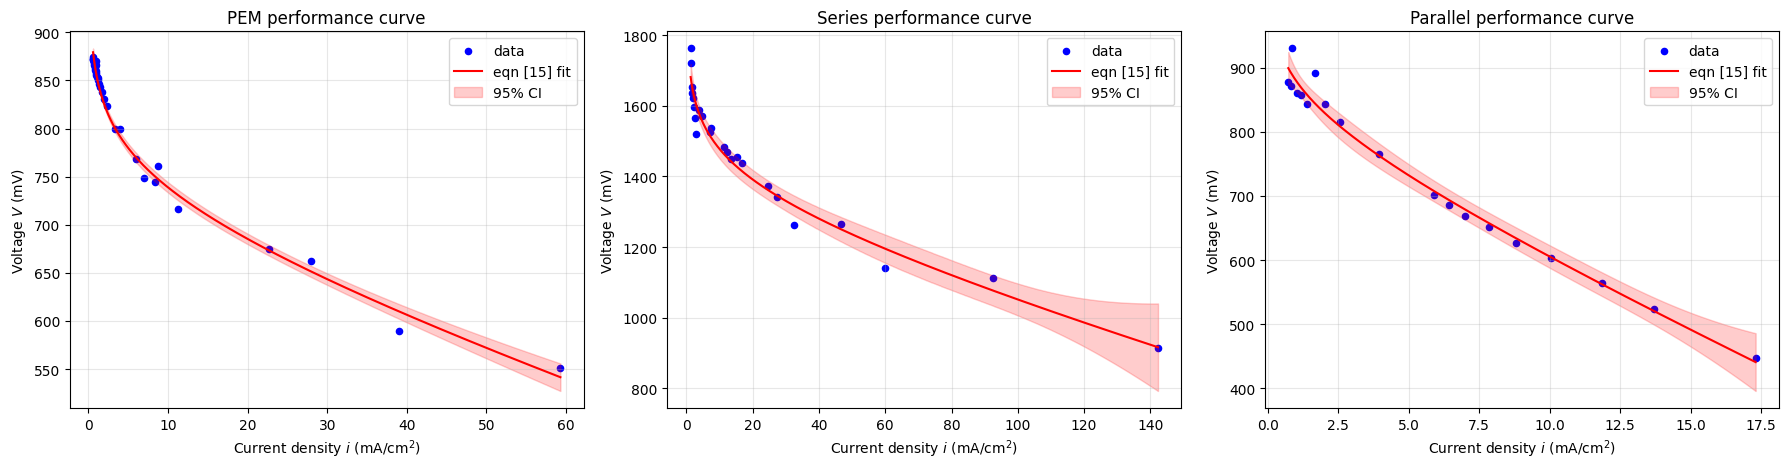

In [14]:
def conf_band(i_fit, p, cov, n_data, level=0.95):
    # Delta method: propagate the parameter covariance through the model.
    # This is the nonlinear analog of the module's confidence-band formula.
    eps = 1e-6
    J = np.array([(model(i_fit, *(p + eps*np.eye(len(p))[k])) - model(i_fit, *p)) / eps
                  for k in range(len(p))]).T
    se = np.sqrt(np.einsum("ij,jk,ik->i", J, cov, J))
    return t.ppf(0.5 + level/2, n_data - len(p)) * se   # t-score instead of 1.96 (small n)

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p)
    band = conf_band(i_fit, p, cov, len(i))

    ax.scatter(i, V, color="b", s=20, label="data")
    ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
    ax.fill_between(i_fit, V_fit - band, V_fit + band, color="r", alpha=0.2, label="95% CI")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Voltage $V$ (mV)")
    ax.set_title(f"{name} performance curve")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

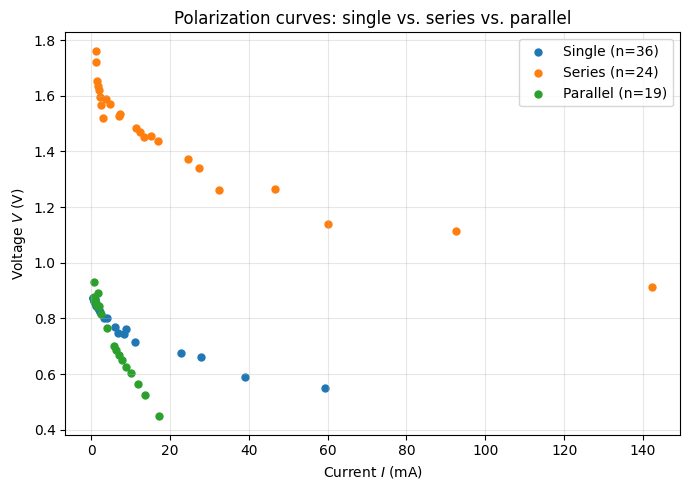

In [8]:
# Scatter: V vs I for single, series, and parallel (Google Sheet "Hydrogen Experiments")
h2_book = gc.open("Hydrogen Experiments")   # the Sheet's title as shown in Drive

def load_tab(tab):
    rows = h2_book.worksheet(tab).get_all_values()[1:]   # skip header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    return np.array(I), np.array(V)

configs = [("Single", "PEM Fuel Cell", "tab:blue"),
           ("Series", "Series", "tab:orange"),
           ("Parallel", "Parallel", "tab:green")]

fig, ax = plt.subplots(figsize=(7, 5))
for label, tab, color in configs:
    I, V = load_tab(tab)
    ax.scatter(I, V, s=25, color=color, label=f"{label} (n={len(I)})")

ax.set_xlabel(r"Current $I$ (mA)")
ax.set_ylabel(r"Voltage $V$ (V)")
ax.set_title("Polarization curves: single vs. series vs. parallel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PEM: p_max = 3.211e-02 W/cm^2 at i = 59.30 mA/cm^2, V = 542 mV
Series: p_max = 1.304e-01 W/cm^2 at i = 142.30 mA/cm^2, V = 917 mV
Parallel: p_max = 7.632e-03 W/cm^2 at i = 17.31 mA/cm^2, V = 441 mV


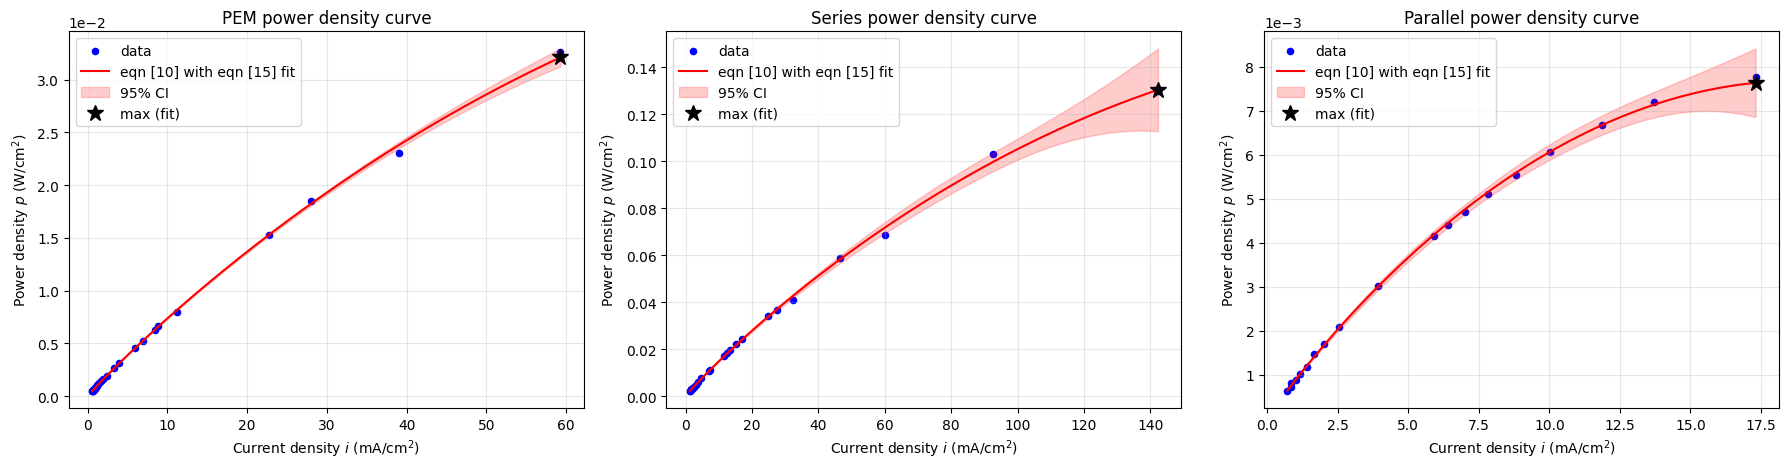

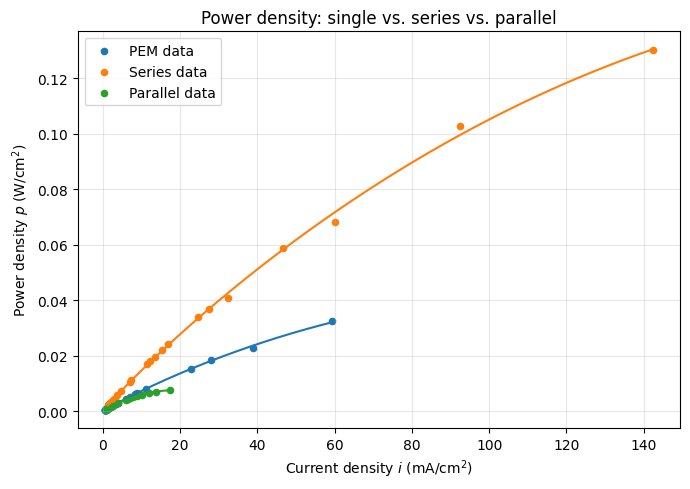

In [15]:
# Power density, eqn [10]: p = V * i
# V [mV] * i [mA/cm^2] = uW/cm^2  ->  x 1e-6  ->  W/cm^2 (handout units)
TO_W = 1e-6

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p_par, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p_par)                  # eqn [15]
    band = conf_band(i_fit, p_par, cov, len(i))

    p_data = V * i * TO_W                         # eqn [10], measured
    p_fit = V_fit * i_fit * TO_W                  # eqn [10] applied to eqn [15] fit
    p_band = band * i_fit * TO_W                  # i is exact, so the band scales by i

    k = np.argmax(p_fit)
    print(f"{name}: p_max = {p_fit[k]:.3e} W/cm^2 at i = {i_fit[k]:.2f} mA/cm^2, "
          f"V = {V_fit[k]:.0f} mV")

    ax.scatter(i, p_data, color="b", s=20, label="data")
    ax.plot(i_fit, p_fit, "r-", label="eqn [10] with eqn [15] fit")
    ax.fill_between(i_fit, p_fit - p_band, p_fit + p_band, color="r", alpha=0.2, label="95% CI")
    ax.plot(i_fit[k], p_fit[k], "k*", ms=12, label="max (fit)")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
    ax.set_title(f"{name} power density curve")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Overlay of all three configurations
fig, ax = plt.subplots(figsize=(7, 5))
for (name, i, V), color in zip(datasets, ["tab:blue", "tab:orange", "tab:green"]):
    p_par, _ = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    ax.scatter(i, V * i * TO_W, s=20, color=color, label=f"{name} data")
    ax.plot(i_fit, model(i_fit, *p_par) * i_fit * TO_W, color=color)
ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
ax.set_title("Power density: single vs. series vs. parallel")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()